# Algorithm 1 on a single Hodgkin–Huxley neuron

This notebook includes the code for the first example of the paper "A Novel Algorithm to Simulate Conductance-based Neuronal Networks".



Algorithm 1 simulates a conductance-based neuron in signal space. Starting from a guess $v^0$ of the whole voltage signal on $[0, T]$, each iteration does two things:

**Step 1: Freeze the memristors** Evaluate every conductance along the current iterate: $g_i^k = \operatorname{G}_i(v^k)$.


**Step 2: Solve the RC circuit.** With the conductances frozen, the voltage obeys a scalar linear time-varying ODE,
$$C_m \dot v^{k+1} = -\sum_i g_i^k(t)\,\bigl(v^{k+1} - E_i\bigr) + u(t), \qquad v^{k+1}(0) = v_0 .$$
which the paper forms as
$$\dot{v}_n^{k+1} = -\eta (t) v_n^{k+1} + \xi (t)$$
and has a closed-form solution as a simple integrator.

The iteration stops once $\max_t |v^{k+1}(t) - v^k(t)| \le \varepsilon$.

In [15]:
import numpy as np
import matplotlib.pyplot as plt

## Parameters

In [16]:
# Simulation window
T_FINAL = 40.0                          # ms - Simulation Window
DT = 0.1                                # ms - Time vector discretization step
t = np.arange(0, T_FINAL + DT / 2, DT)  # Time vector

# Hodgkin–Huxley neuron
C_M = 1.0                               # membrane capacitance (µF/cm²)
G_NA, G_K, G_L = 120.0, 36.0, 0.3       # maximal conductances (mS/cm²)
E_NA, E_K, E_L = 50.0, -77.0, -54.387   # reversal potentials (mV)
V0 = -65.0                              # initial voltage (mV)
M0, H0, N0 = 0.0, 0.6, 0.3              # initial gate values

# Injected current: Gaussian pulse, peak 10 µA/cm² at 17.5 ms, width 1 ms.
# Defined as a function of time so that Algorithm 1 (which samples it on the grid t)
# and the reference integrator (which evaluates it at its own adaptive times) use the
# same input.

def injected_current(time):
    return 10.0 * np.exp(-0.5 * ((time - 17.5) / 1.0) ** 2)

u = injected_current(t)

# Solver
V_GUESS = -60.0   # constant initial guess v^0(t) (mV)
TOL = 1e-3        # stopping tolerance ε          (mV)
MAX_ITERS = 300   # Maximum number of iteration allowed

## Linear time-varying solver

Both steps reduce to scalar LTV equations of the form $\dot x = -a(t)\,x + b(t)$. On each time step, $a$ and $b$ are replaced by their averages and the equation is solved exactly. Three closed-form numerical solvers are provided: `solve_ltv` (2nd order), `solve_ltv_simpson` (Simpson on even nodes) and `solve_ltv_high_order` (order 2, 4 or 6; centred polynomial interpolation of $a$ and $b$ with Gauss quadrature, same normalization as the Simpson solver). `solve_ltv_high_order` is used below. **Bear in mind that the `high_order` solver requires smoothness in input so in case of discontinuous inputs (like steps), the closed-form solver needs to be adapted.**

In [17]:
def solve_ltv(a, b, x0):
    """Solve x' = -a(t) x + b(t), x(0) = x0, on the grid t (a > 0)."""
    a_avg = 0.5 * (a[:-1] + a[1:])
    b_avg = 0.5 * (b[:-1] + b[1:])
    decay = np.exp(-a_avg * DT)
    x = np.empty_like(t)
    x[0] = x0
    for i in range(len(t) - 1):
        x[i + 1] = decay[i] * x[i] + (1 - decay[i]) * b_avg[i] / a_avg[i]
    return x


def solve_ltv_simpson(a, b, x0):
    """Solve x' = -a(t) x + b(t), x(0) = x0, on the grid t (a > 0, odd number of points).

    Even nodes: normalized Simpson exponential step over two cells.
    Odd nodes:  normalized trapezoidal exponential step over one cell.
    Each update is x_new = e^{-A} x_old + (1 - e^{-A}) * sum(w*b) / sum(w*a) with
    positive weights w: a convex combination of x_old and the ratios b/a, so the
    scheme is unconditionally stable and gates stay in [0, 1].
    """
    if len(t) % 2 == 0:
        raise ValueError("solve_ltv_simpson needs an odd number of grid points (T_FINAL / DT even).")
    h = 2 * DT
    x = np.empty_like(t)
    x[0] = x0
    for i in range(0, len(t) - 2, 2):
        a0, a1, a2 = a[i:i + 3]
        b0, b1, b2 = b[i:i + 3]

        # Full step t_i -> t_{i+2} (Simpson, midpoint t_{i+1})
        A = h / 6 * (a0 + 4 * a1 + a2)               # integral of a over the step
        A_mid = h / 24 * (-a0 + 8 * a1 + 5 * a2)     # integral of a from the midpoint to the end
        w0, w1, w2 = np.exp(-A), 4 * np.exp(-A_mid), 1.0
        x[i + 2] = np.exp(-A) * x[i] + (1 - np.exp(-A)) * (w0 * b0 + w1 * b1 + w2 * b2) / (w0 * a0 + w1 * a1 + w2 * a2)

        # Midpoint t_i -> t_{i+1} (trapezoid)
        A_half = DT / 2 * (a0 + a1)
        w0 = np.exp(-A_half)
        x[i + 1] = np.exp(-A_half) * x[i] + (1 - np.exp(-A_half)) * (w0 * b0 + b1) / (w0 * a0 + a1)
    return x

# ---------------------------------------------------------------------------
# High-order solver (order 2, 4 or 6)
# ---------------------------------------------------------------------------
from numpy.polynomial import polynomial as P

try:  # optional: compile the sequential recurrence with numba (~2.5x faster)
    from numba import njit
except ImportError:
    njit = None


def _recurrence_kernel(d, f, x0, out):
    """out[k, i+1] = d[k, i] * out[k, i] + f[k, i], out[k, 0] = x0[k]."""
    for k in range(d.shape[0]):
        x = x0[k]
        out[k, 0] = x
        for i in range(d.shape[1]):
            x = d[k, i] * x + f[k, i]
            out[k, i + 1] = x


if njit is not None:
    _recurrence_kernel = njit(cache=True)(_recurrence_kernel)


def _recurrence(d, f, x0):
    """Run x_{i+1} = d_i x_i + f_i along the last axis; leading axes are a batch."""
    shape = d.shape
    d2 = np.ascontiguousarray(d.reshape(-1, shape[-1]))
    f2 = np.ascontiguousarray(f.reshape(-1, shape[-1]))
    x02 = np.broadcast_to(np.asarray(x0, dtype=float), shape[:-1]).reshape(-1).copy()
    out = np.empty((d2.shape[0], shape[-1] + 1))
    _recurrence_kernel(d2, f2, x02, out)
    return out.reshape(shape[:-1] + (shape[-1] + 1,))


_HO_TABLES = {}


def _high_order_tables(n, order):
    """Interpolation/quadrature weights for every cell of an n-point grid (cached)."""
    key = (n, order)
    if key not in _HO_TABLES:
        nq = order // 2                                     # Gauss points per cell
        g, w = np.polynomial.legendre.leggauss(nq)
        tau_q, w_q = 0.5 * (g + 1.0), 0.5 * w               # nodes/weights on [0, 1]
        ncell = n - 1
        start = np.clip(np.arange(ncell) - (order // 2 - 1), 0, n - order)  # centred stencil
        shift = start - np.arange(ncell)                    # stencil offset rel. to cell start
        per_shift = {}
        for s in np.unique(shift):
            offsets = s + np.arange(order)
            val = np.zeros((nq, order)); tail = np.zeros((nq, order)); full = np.zeros(order)
            for k in range(order):
                others = np.delete(offsets, k)
                c = P.polyfromroots(others) / np.prod(offsets[k] - others)   # Lagrange basis
                ci = P.polyint(c)
                val[:, k] = P.polyval(tau_q, c)                              # value at tau_q
                tail[:, k] = P.polyval(1.0, ci) - P.polyval(tau_q, ci)       # int_{tau_q}^1
                full[k] = P.polyval(1.0, ci) - P.polyval(0.0, ci)            # int_0^1
            per_shift[s] = (val, tail, full)
        _HO_TABLES[key] = (
            start[:, None] + np.arange(order)[None, :],
            np.stack([per_shift[s][0] for s in shift]),
            np.stack([per_shift[s][1] for s in shift]),
            np.stack([per_shift[s][2] for s in shift]),
            w_q,
        )
    return _HO_TABLES[key]


def solve_ltv_high_order(a, b, x0, order=6):
    """Solve x' = -a(t) x + b(t), x(0) = x0, on the grid t (a >= 0), with order 2, 4 or 6.

    On each cell [t_i, t_{i+1}], a and b are interpolated by a polynomial of degree
    order-1 through the nearest `order` grid nodes (centred: a and b are known on the
    whole grid, so "future" samples can be used). The exact solution
        x_{i+1} = e^{-A} x_i + int e^{-int_s^{t_{i+1}} a} b(s) ds
    is then evaluated with A and the tail integrals of a computed exactly from the
    polynomial, and the forcing integral by Gauss-Legendre quadrature. As in
    solve_ltv_simpson, the forcing is normalized,
        x_{i+1} = e^{-A} x_i + (1 - e^{-A}) * sum(w K b) / sum(w K a),
    which is exact for b = a and keeps the scheme unconditionally stable.
    order=2 reproduces solve_ltv exactly.

    Leading axes of a and b are a batch: shape (..., len(t)) solves several
    equations at once (e.g. all gates, or all neurons of a network).
    """
    if order not in (2, 4, 6):
        raise ValueError("order must be 2, 4 or 6")
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    idx, val, tail, full, w_q = _high_order_tables(a.shape[-1], order)
    Sa, Sb = a[..., idx], b[..., idx]                       # stencil values, (..., ncell, order)
    A = DT * np.einsum("ck,...ck->...c", full, Sa)          # int of a over each cell
    K = w_q * np.exp(-DT * np.einsum("cqk,...ck->...cq", tail, Sa))   # decay kernel at Gauss pts
    num = (K * np.einsum("cqk,...ck->...cq", val, Sb)).sum(-1)
    den = (K * np.einsum("cqk,...ck->...cq", val, Sa)).sum(-1)
    safe = np.abs(den) > 1e-300
    gain = np.where(safe, -np.expm1(-A) / np.where(safe, den, 1.0), DT)  # -> DT as a -> 0
    return _recurrence(np.exp(-A), gain * num, x0)

## Step 1: conductances

Each gate $x \in \{m, h, n\}$ obeys $\dot x = \alpha_x(v)(1 - x) - \beta_x(v)\,x$, which is an LTV equation once the voltage signal is given. Solving it along $v^k$ gives the conductance signal of each branch.

In [18]:
def alpha_m(v): return 0.1 * (v + 40.0 + 1e-5) / (1.0 - np.exp(-(v + 40.0 + 1e-5) / 10.0))
def beta_m(v):  return 4.0 * np.exp(-(v + 65.0) / 18.0)
def alpha_h(v): return 0.07 * np.exp(-(v + 65.0) / 20.0)
def beta_h(v):  return 1.0 / (1.0 + np.exp(-(v + 35.0) / 10.0))
def alpha_n(v): return 0.01 * (v + 55.0 + 1e-5) / (1.0 - np.exp(-(v + 55.0 + 1e-5) / 10.0))
def beta_n(v):  return 0.125 * np.exp(-(v + 65.0) / 80.0)


def gate(alpha, beta, x0):
    # return solve_ltv_simpson(alpha + beta, alpha, x0)
    return solve_ltv_high_order(alpha + beta, alpha, x0)


E = np.array([E_NA, E_K, E_L])   # reversal potential of each branch


def conductances(v):
    """Step 1: map the voltage signal v to the conductance signal of each branch."""
    m = gate(alpha_m(v), beta_m(v), M0)
    h = gate(alpha_h(v), beta_h(v), H0)
    n = gate(alpha_n(v), beta_n(v), N0)
    return np.array([G_NA * m**3 * h, G_K * n**4, np.full_like(v, G_L)])

## Algorithm 1

In [19]:
def algorithm_1(v):
    for k in range(1, MAX_ITERS + 1):
        g = conductances(v)                                                        # Step 1
        v_next = solve_ltv_high_order(g.sum(axis=0) / C_M, (E @ g + u) / C_M, V0)  # Step 2
        converged = np.max(np.abs(v_next - v)) <= TOL
        v = v_next
        if converged:
            print(f"Converged in {k} iterations.")
            return v, k
    print(f"Did not converge in {MAX_ITERS} iterations.")
    return v, MAX_ITERS

v, n_iters = algorithm_1(np.full_like(t, V_GUESS))

Converged in 21 iterations.


## Reference solution (numerical integration)

To verify Algorithm 1, the full four-dimensional Hodgkin–Huxley ODE in $(v, m, h, n)$ is integrated directly with an adaptive 8th-order Runge–Kutta method (DOP853) at tolerance $10^{-12}$, and cross-checked with an independent implicit method (Radau).

**Fixed grid vs. adaptive steps.** Algorithm 1 produces values on the fixed grid `t` (spacing `DT`). The integrator chooses its own, uneven steps from the error tolerance, so its internal step points do not coincide with `t`. The two are compared like this:

* Both solve the *same* problem: the parameters, gating functions, initial state `(V0, M0, H0, N0)`, capacitance `C_M` and the input function `injected_current` are the ones defined above, not copies.
* The integrator is run with `dense_output=True`, which gives a continuous 7th-order interpolant between its steps, accurate to the integration tolerance at *any* time. The reference is evaluated from it **exactly at the grid points of Algorithm 1**, so the comparison is pointwise at identical times. No linear interpolation is involved.
* The step sizes of the integrator are controlled by the tolerance, not by `DT`, so its accuracy does not depend on Algorithm 1's grid. `MAX_STEP` only caps the step length so the 1 ms current pulse cannot be stepped over while the neuron is at rest.
* The remaining difference is therefore the discretization error of Algorithm 1 (sampling of $u$ and the conductances on the grid, and the LTV solver), plus the integrator error, which the DOP853 vs. Radau check bounds at about $10^{-8}$ mV.


DOP853: 649 adaptive steps, step sizes 6.12e-03-1.00e-01 ms
max |DOP853 - Radau| = 6.71e-09 mV


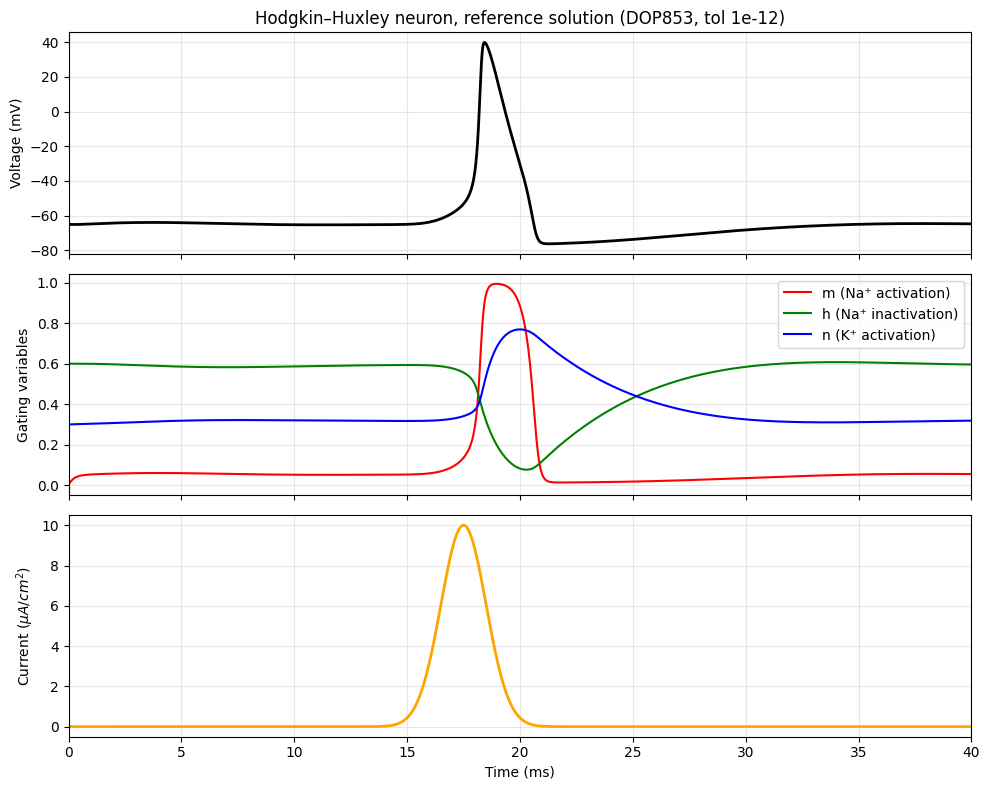

In [20]:
"""High-precision reference solution of the Hodgkin–Huxley neuron ("ground truth").

Integrates the full HH ODE in (v, m, h, n) with an adaptive 8th-order Runge–Kutta
method (DOP853) at tolerance 1e-12. The input is the smooth Gaussian pulse
`injected_current`, so no restarts at switching times are needed; MAX_STEP keeps
the integrator from stepping over the pulse while the neuron is at rest.
A second, implicit solver (Radau) is run as an independent cross-check.

All parameters, gating functions, initial values and the input are the ones
defined above for Algorithm 1. Units: mV, ms, µA/cm², mS/cm², µF/cm².
"""
from scipy.integrate import solve_ivp

RTOL = ATOL = 1e-12   # below ~1e-13 scipy clamps rtol to its floor (100 * machine eps)
DT_OUT = 0.001        # ms, spacing of the saved/plotted samples (does not affect accuracy)
MAX_STEP = 0.1        # ms, upper bound on the integrator step (safeguard, see above)


def hh_rhs(time, y):
    v_, m_, h_, n_ = y
    i_ion = G_NA * m_**3 * h_ * (v_ - E_NA) + G_K * n_**4 * (v_ - E_K) + G_L * (v_ - E_L)
    return [(injected_current(time) - i_ion) / C_M,
            alpha_m(v_) * (1 - m_) - beta_m(v_) * m_,
            alpha_h(v_) * (1 - h_) - beta_h(v_) * h_,
            alpha_n(v_) * (1 - n_) - beta_n(v_) * n_]


def simulate(method):
    sol = solve_ivp(hh_rhs, (0.0, T_FINAL), [V0, M0, H0, N0], method=method,
                    rtol=RTOL, atol=ATOL, max_step=MAX_STEP, dense_output=True)
    if not sol.success:
        raise RuntimeError(f"{method} failed: {sol.message}")
    return sol


ref = simulate("DOP853")
ref_check = simulate("Radau")

# Fine uniform samples for plotting and saving
t_ni = np.linspace(0.0, T_FINAL, int(round(T_FINAL / DT_OUT)) + 1)
v_ni, m_ni, h_ni, n_ni = ref.sol(t_ni)
print(f"DOP853: {ref.t.size - 1} adaptive steps, step sizes {np.diff(ref.t).min():.2e}"
      f"-{np.diff(ref.t).max():.2e} ms")
print(f"max |DOP853 - Radau| = {np.max(np.abs(v_ni - ref_check.sol(t_ni)[0])):.2e} mV")

np.savez("data_NI_HH_High_Precision_Gaussian.npz", t=t_ni, v=v_ni, m=m_ni, h=h_ni, n=n_ni)

# Plot
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax1.plot(t_ni, v_ni, "k", lw=2)
ax1.set_ylabel("Voltage (mV)")
ax1.set_title(f"Hodgkin–Huxley neuron, reference solution (DOP853, tol {RTOL:g})")

ax2.plot(t_ni, m_ni, "r", label="m (Na⁺ activation)")
ax2.plot(t_ni, h_ni, "g", label="h (Na⁺ inactivation)")
ax2.plot(t_ni, n_ni, "b", label="n (K⁺ activation)")
ax2.set_ylabel("Gating variables")
ax2.legend(loc="upper right")
ax3.plot(t_ni, injected_current(t_ni), "orange", lw=2)
ax3.set_xlabel("Time (ms)")
ax3.set_ylabel(r"Current ($\mu A/cm^2$)")
for ax in (ax1, ax2, ax3):
    ax.grid(alpha=0.3)
ax3.set_xlim(0, T_FINAL)
plt.tight_layout()
plt.show()


## Comparison: Algorithm 1 vs. reference

The reference is evaluated from its continuous interpolant at the grid points `t` of Algorithm 1, and the gating variables of Algorithm 1 are recovered from its converged voltage with the same `gate` solver used inside the algorithm.

Algorithm 1: 21 iterations on a fixed grid of 400 steps (DT = 0.1 ms)
max |v - v_ref|  = 1.564e-01 mV  (at t = 18.2 ms)
RMS(v - v_ref)   = 1.202e-02 mV
max |m - m_ref|  = 5.177e-04
max |h - h_ref|  = 2.234e-04
max |n - n_ref|  = 1.131e-04


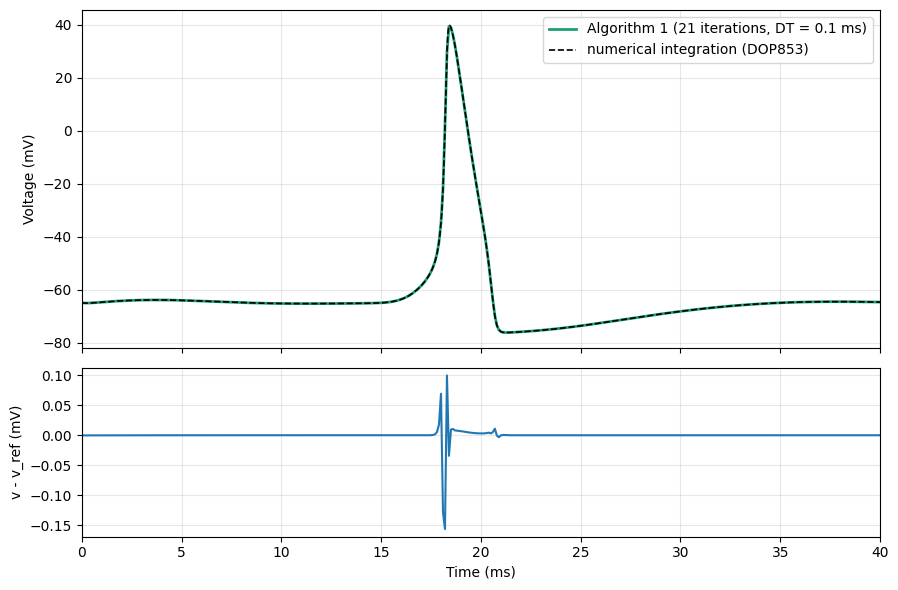

In [21]:
# Reference at the Algorithm 1 grid points (from the dense output, no interpolation of samples)
v_ref, m_ref, h_ref, n_ref = ref.sol(t)
error = v - v_ref

# Gates of Algorithm 1 along its converged voltage
m_a1 = gate(alpha_m(v), beta_m(v), M0)
h_a1 = gate(alpha_h(v), beta_h(v), H0)
n_a1 = gate(alpha_n(v), beta_n(v), N0)

print(f"Algorithm 1: {n_iters} iterations on a fixed grid of {len(t) - 1} steps (DT = {DT} ms)")
print(f"max |v - v_ref|  = {np.max(np.abs(error)):.3e} mV  (at t = {t[np.argmax(np.abs(error))]:.1f} ms)")
print(f"RMS(v - v_ref)   = {np.sqrt(np.mean(error**2)):.3e} mV")
for name, xa, xr in (("m", m_a1, m_ref), ("h", h_a1, h_ref), ("n", n_a1, n_ref)):
    print(f"max |{name} - {name}_ref|  = {np.max(np.abs(xa - xr)):.3e}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(t, v, color="#1D9E75", lw=2, label=f"Algorithm 1 ({n_iters} iterations, DT = {DT} ms)")
ax1.plot(t_ni, v_ni, "k--", lw=1.2, label="numerical integration (DOP853)")
ax1.set_ylabel("Voltage (mV)")
ax1.legend(loc="upper right")
ax2.plot(t, error, lw=1.5)
ax2.set_xlabel("Time (ms)")
ax2.set_ylabel("v - v_ref (mV)")
ax2.set_xlim(0, T_FINAL)
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
